# EN.605.631 — Jointly Distributed Random Variables with R (Chapter 6) — Notebook Shell

**Format:** Jupyter Notebook (**R kernel**)  
**Estimated time:** ~5 hours  
**Total points:** 100

Follow the instructions in the assignment. This shell provides stubs and plotting scaffolds.

## Environment & Setup

In [1]:
# Show environment
R.version.string
sessionInfo()

# Reproducibility
set.seed(631)

# Optional packages (commented). Base R preferred.
# suppressPackageStartupMessages({
#   library(ggplot2)
#   library(dplyr)
#   library(tidyr)
#   library(reshape2)
# })

[1] "R version 4.6.1 (2026-06-24 ucrt)"

R version 4.6.1 (2026-06-24 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=English_United States.utf8 
[2] LC_CTYPE=English_United States.utf8   
[3] LC_MONETARY=English_United States.utf8
[4] LC_NUMERIC=C                          
[5] LC_TIME=English_United States.utf8    

time zone: America/New_York
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] digest_0.6.39     IRdisplay_1.1     base64enc_0.1-6   fastmap_1.2.0    
 [5] glue_1.8.1        htmltools_0.5.9   repr_1.1.7        lifecycle_1.0.5  
 [9] cli_3.6.6         vctrs_0.7.3       textshaping_1.0.5 pbdZMQ_0.3-14    
[13] systemfonts_1.3.2 compiler_4.6.1    tools_4.6.1       ragg_1.5.2       
[17] evaluate_1.0.5    pillar_1.11.1     rlang_1.3.0       jsonlite_2.0.0   
[21] crayon_1.5.3      IRkernel_1.

## Helper Utilities (you may add to these)

In [2]:
# Monte Carlo SE for a mean
mc_se_mean <- function(x) sd(x)/sqrt(length(x))

# Wald 95% CI for a Bernoulli proportion
ci95_prop <- function(p_hat, n){
  se <- sqrt(p_hat*(1-p_hat)/n)
  c(lower = max(0, p_hat - 1.96*se),
    upper = min(1, p_hat + 1.96*se))
}

---
## Problem 1 — Joint CDF/pmf basics & marginals (10 pts)

Urn: draw 3 without replacement from 3 red, 4 white, 5 blue.  
Let \(X\)=# red, \(Y\)=# white.

1) Derive the **joint pmf** \(p_{X,Y}(i,j)\) and **marginals**.  
2) Enumerate all outcomes to validate; compute \(P\{X\ge1, Y=2\}\) and \(P\{X>Y\}\) via table, enumeration, and Monte Carlo with 95% CIs.

**Your plan/derivation:** 

When $X=i$ and $Y=j$, the number of ways to choose 

- $i$ red balls,
- $j$ white balls,
- $3-i-j$ blue balls

is $\binom{3}{i}\binom{4}{j}\binom{5}{3-i-j}$

The number of ways to choose any $3$ balls is $\binom{12}{3}$

$p_{X,Y}(i,j)=\frac{\binom{3}{i}\binom{4}{j}\binom{5}{3-i-j}}{\binom{12}{3}},\qquad i,j\ge 0,\ i+j\le 3$

and $p_{X,Y}(i,j)=0$ otherwise

The marginals are:

$p_X(i)=\sum_j p_{X,Y}(i,j)$

and

$p_Y(j)=\sum_i p_{X,Y}(i,j)$

In [3]:
# === Analytic table ===
# TODO: fill a data frame with i=0..3, j=0..3 with valid counts and probabilities
pmf_tbl <- expand.grid(i = 0:3, j = 0:3)
pmf_tbl$count <- with(pmf_tbl, choose(3, i) * choose(4, j) * choose(5, 3 - i - j))
pmf_tbl$prob  <- pmf_tbl$count / choose(12, 3)

joint  <- matrix(pmf_tbl$prob,  nrow = 4, ncol = 4, dimnames = list(i = 0:3, j = 0:3))
counts <- matrix(pmf_tbl$count, nrow = 4, ncol = 4, dimnames = list(i = 0:3, j = 0:3))
counts
round(joint, 4)

# Check marginals sum to 1
pX <- rowSums(joint)
pY <- colSums(joint)
pX; pY
c(sum(pX), sum(pY), sum(joint))

,0,1,2,3
0,10,40,30,4
1,30,60,18,0
2,15,12,0,0
3,1,0,0,0


,0,1,2,3
0,0.0455,0.1818,0.1364,0.0182
1,0.1364,0.2727,0.0818,0.0000
2,0.0682,0.0545,0.0000,0.0000
3,0.0045,0.0000,0.0000,0.0000


0           1           2           3 
0.381818182 0.490909091 0.122727273 0.004545455

0          1          2          3 
0.25454545 0.50909091 0.21818182 0.01818182

[1] 1 1 1

In [4]:
# === Enumeration ===
# Enumerate all 12 choose 3 draws without replacement with colors R,W,B (3,4,5)
# outcomes <- ...
# Compute X, Y; empirical probs
outcomes <- combn(12, 3)
p_A_table <- sum(joint[as.character(1:3), "2"])
p_B_table <- sum(pmf_tbl$prob[pmf_tbl$i > pmf_tbl$j])
print("Analytic joint pmf from table of i reds and j whites:")
round(joint, 4)
print("Probabilities by Table:")
c("P(X>=1, Y=2)" = p_A_table, "P(X>Y)" = p_B_table)

balls <- rep(c("R", "W", "B"), times = c(3, 4, 5))
X_enum <- apply(outcomes, 2, function(s) sum(balls[s] == "R"))
Y_enum <- apply(outcomes, 2, function(s) sum(balls[s] == "W"))
draws_df <- data.frame(draw = 1:ncol(outcomes), X = X_enum, Y = Y_enum)
enum_df <- as.data.frame(
    table(i = factor(draws_df$X, levels = 0:3),
          j = factor(draws_df$Y, levels = 0:3)),
    responseName = "count"
)
enum_df$i <- as.integer(as.character(enum_df$i))
enum_df$j <- as.integer(as.character(enum_df$j))
enum_df$prob <- enum_df$count / ncol(outcomes)
print("Empirical joint pmf from enumeration of i reds and j whites:")
enum_df$prob <- round(enum_df$prob, 4)
enum_tbl <- matrix(enum_df$prob, nrow = 4, ncol = 4, dimnames = list(i = 0:3, j = 0:3))
round(enum_tbl, 4)

p_A_enum <- mean(X_enum >= 1 & Y_enum == 2)
p_B_enum <- mean(X_enum > Y_enum)
print("Probabilities by Enumeration:")
c("P(X>=1, Y=2)" = p_A_enum, "P(X>Y)" = p_B_enum)

[1] "Analytic joint pmf from table of i reds and j whites:"


,0,1,2,3
0,0.0455,0.1818,0.1364,0.0182
1,0.1364,0.2727,0.0818,0.0000
2,0.0682,0.0545,0.0000,0.0000
3,0.0045,0.0000,0.0000,0.0000


[1] "Probabilities by Table:"


P(X>=1, Y=2)       P(X>Y) 
  0.08181818   0.26363636

[1] "Empirical joint pmf from enumeration of i reds and j whites:"


,0,1,2,3
0,0.0455,0.1818,0.1364,0.0182
1,0.1364,0.2727,0.0818,0.0000
2,0.0682,0.0545,0.0000,0.0000
3,0.0045,0.0000,0.0000,0.0000


[1] "Probabilities by Enumeration:"


P(X>=1, Y=2)       P(X>Y) 
  0.08181818   0.26363636

In [5]:
# === Monte Carlo ===
# N <- 1e5
# Simulate draws via sample(rep(c("R","W","B"), times=c(3,4,5)), 3, replace=FALSE)
# Compute indicators and 95% CIs
N <- 1e5
urn <- rep(c("R", "W", "B"), times = c(3, 4, 5))
sims <- replicate(N, sample(urn, 3, replace = FALSE))
X_mc <- colSums(sims == "R")
Y_mc <- colSums(sims == "W")

wald <- function(ind, N) {
  p  <- mean(ind)
  se <- sqrt(p * (1 - p) / N)
  c(est = p, lower = p - 1.96 * se, upper = p + 1.96 * se)
}
mc_A <- wald(X_mc >= 1 & Y_mc == 2, N)
mc_B <- wald(X_mc > Y_mc, N)
mc_A; mc_B

est      lower      upper 
0.08256000 0.08085419 0.08426581

est     lower     upper 
0.2629800 0.2602513 0.2657087

In [6]:
# === Report ===
# list(table_based=..., enumeration=..., monte_carlo=list(est=..., ci=...))
list(table_based = list(A = p_A_table, B = p_B_table),
    enumeration = list(A = p_A_enum, B = p_B_enum),
    monte_carlo = list(
        est = c(A = unname(mc_A["est"]), B = unname(mc_B["est"])),
        ci  = list(A = unname(mc_A[c("lower", "upper")]), B = unname(mc_B[c("lower", "upper")]))
    )
)

$table_based
$table_based$A
[1] 0.08181818

$table_based$B
[1] 0.2636364


$enumeration
$enumeration$A
[1] 0.08181818

$enumeration$B
[1] 0.2636364


$monte_carlo
$monte_carlo$est
      A       B 
0.08256 0.26298 

$monte_carlo$ci
$monte_carlo$ci$A
[1] 0.08085419 0.08426581

$monte_carlo$ci$B
[1] 0.2602513 0.2657087

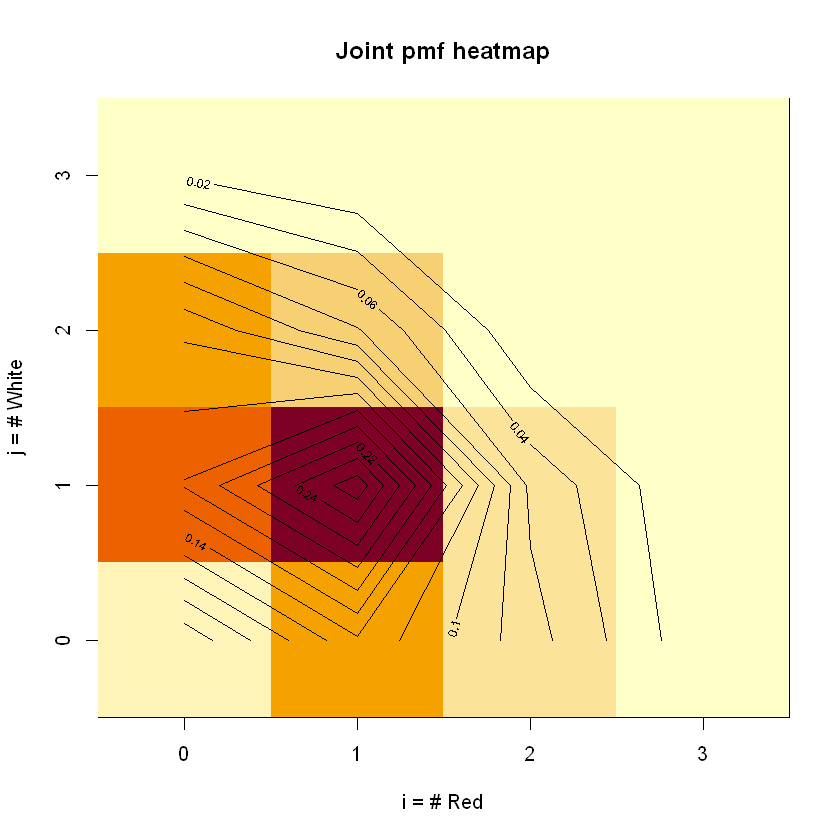

In [7]:
# === Plot scaffold: heatmap of p_{X,Y} ===
# Example: image() or persp() or tile via ggplot if used.
# grid_i <- 0:3; grid_j <- 0:3
# Z <- matrix(0, nrow=length(grid_i), ncol=length(grid_j))
# Fill Z with pmf values in the same order as axes
# image(grid_i, grid_j, Z, xlab="i = # Red", ylab="j = # White", main="Joint pmf heatmap")
# contour(grid_i, grid_j, Z, add=TRUE)
grid_i <- 0:3; grid_j <- 0:3
Z <- matrix(0, nrow = length(grid_i), ncol = length(grid_j))
for (a in seq_along(grid_i)) for (b in seq_along(grid_j)) {
  Z[a, b] <- pmf_tbl$prob[pmf_tbl$i == grid_i[a] & pmf_tbl$j == grid_j[b]]
}
image(grid_i, grid_j, Z, xlab="i = # Red", ylab="j = # White", main="Joint pmf heatmap")
contour(grid_i, grid_j, Z, add=TRUE)

---
## Problem 2 — Independence diagnostics (discrete & continuous) (12 pts)

(a) For \(f(x,y)=cxy\) on \(0<x<1, 0<y<1, x+y<1\): find \(c\), marginals, and assess independence.  
(b) Simulate \(10^6\) draws via accept–reject; estimate Cov, \(\rho\); compare \(f\) vs \(f_X f_Y\) on a grid.

**Your plan/derivation:** _(brief)_

The density will integrate to 1 over $\{x>0, y>0, x+y<1\}$:

$1=\int_0^1\int_0^{1-x} cxy\,dy\,dx=c\int_0^1 x\cdot\frac{(1-x)^2}{2}\,dx=  \frac{c}{2}\int_0^1\left(x-2x^2+x^3\right)dx=\frac{c}{2}\left[\frac{x^2}{2}-\frac{2x^3}{3}+\frac{x^4}{4}\right]_0^1=\frac{c}{2}\left(\frac12-\frac23+\frac14\right) =\frac{c}{2}\left(\frac{6}{12}-\frac{8}{12}+\frac{3}{12}\right)=\frac{c}{2}\left(\frac{1}{12}\right)=\frac{c}{24}$

$c=24$

$f_X(x)=\int_0^{1-x}24xy\,dy=12x(1-x)^2$ for $0<x<1$

$f_Y(y)=12y(1-y)^2$, $0<y<1$

$f_X(x)f_Y(y)=144\,xy(1-x)^2(1-y)^2 \neq f_{X,Y}(x, y)=24xy$

so $X$ and $Y$ are not independent

In [8]:
# === Part (a) analytic ===
# Compute c by integrating over the triangle {x>0,y>0,x+y<1}
# Derive f_X and f_Y; discuss independence.
inner <- function(x) sapply(x, function(xx) integrate(function(y) xx * y, 0, 1 - xx)$value)
int_xy <- integrate(inner, 0, 1)$value
c_val <- 1 / int_xy
c_val

fX <- function(x) 12 * x * (1 - x)^2
fY <- function(y) 12 * y * (1 - y)^2
integrate(fX, 0, 1)$value

EX <- integrate(function(x) x * fX(x), 0, 1)$value
EXY <- 2 / 15
cov_exact <- EXY - EX^2
rho_exact <- cov_exact / (integrate(function(x) x^2 * fX(x), 0, 1)$value - EX^2)
c(EX = EX, Cov = cov_exact, rho = rho_exact)

[1] 24

[1] 1

EX         Cov         rho 
 0.40000000 -0.02666667 -0.66666667

In [9]:
# === Part (b) simulation (accept-reject) ===
N <- 1e6
# Simulate candidates U,V ~ Unif(0,1) restricted to triangle, accept with prob proportional to x*y.
# Hints: propose (X,Y) uniform on triangle via (U1,U2): let x=U1*(1-U2), y=U2*(1-U1), or simple rejection from square with x+y<1.
M <- 7e6
u <- runif(M)
v <- runif(M)
in_tri <- (u + v < 1)
accept <- in_tri & (runif(M) < 4 * u * v)
stopifnot(sum(accept) >= N)
X <- u[accept][1:N]
Y <- v[accept][1:N]

# Store covariance, correlation; grid-based comparison of f vs f_X f_Y.
cov_hat <- cov(X, Y)
rho_hat <- cor(X, Y)
c(accept_rate = mean(accept), Cov = cov_hat, rho = rho_hat, Cov_exact = cov_exact, rho_exact = rho_exact)

accept_rate         Cov         rho   Cov_exact   rho_exact 
 0.16668429 -0.02667061 -0.66634216 -0.02666667 -0.66666667

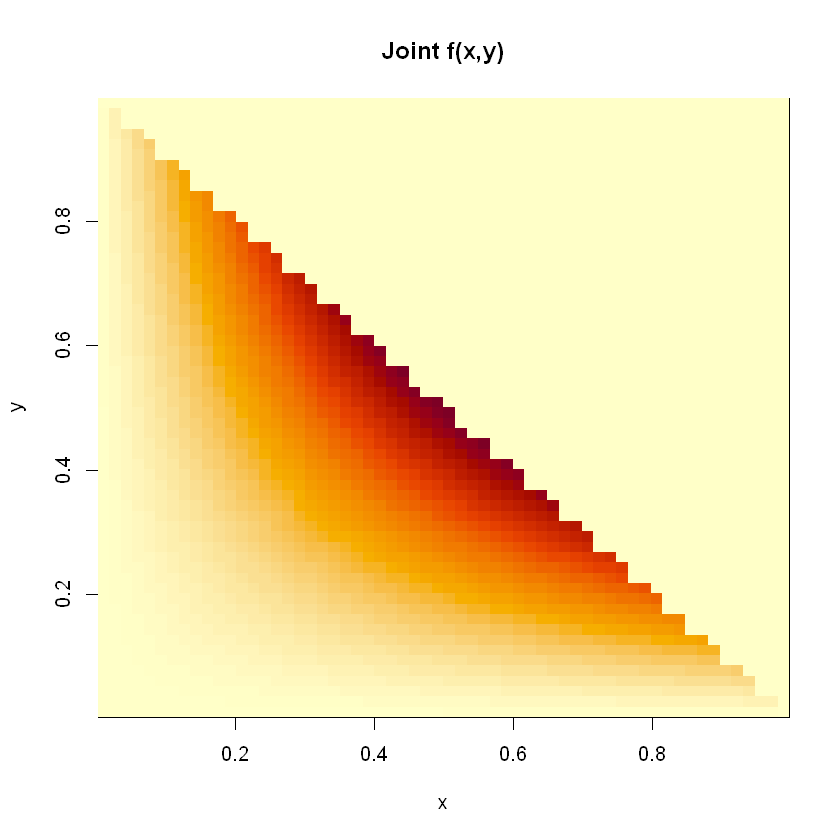

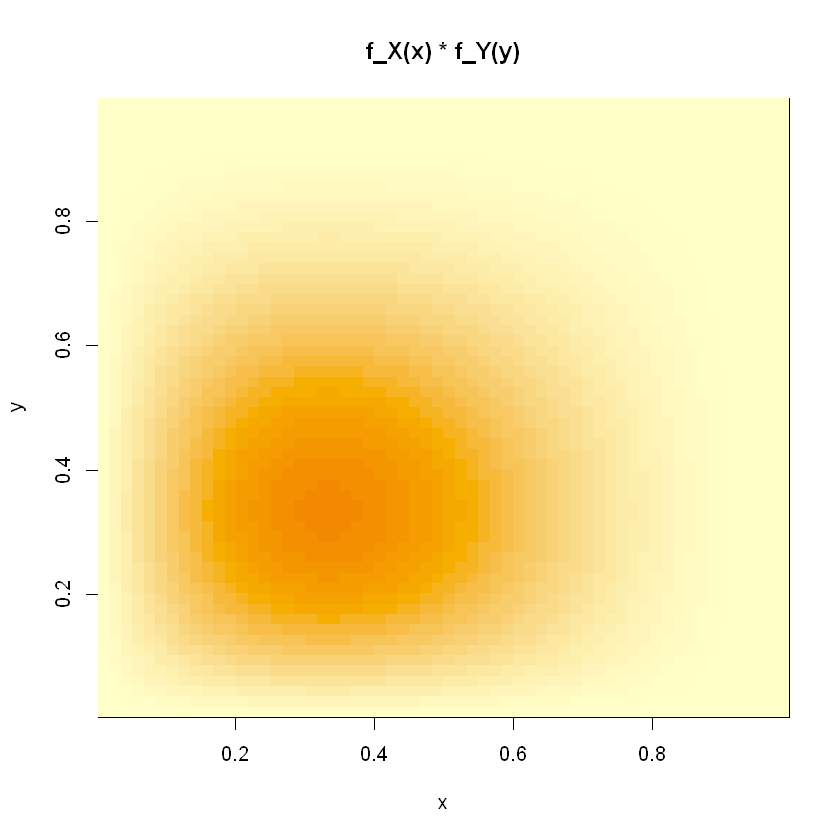

In [10]:
# === Plot scaffold ===
# Prepare a coarse grid; compute f and product of marginals; use image() or contour()
g  <- seq(0.01, 0.99, length.out = 60)
f_joint <- outer(g, g, function(x, y) ifelse(x + y < 1, 24 * x * y, 0))
f_prod  <- outer(g, g, function(x, y) fX(x) * fY(y))

zmax <- max(f_joint, f_prod)
image(g, g, f_joint, zlim = c(0, zmax), col = hcl.colors(50, "YlOrRd", rev = TRUE), xlab = "x", ylab = "y", main = "Joint f(x,y)")
image(g, g, f_prod,  zlim = c(0, zmax), col = hcl.colors(50, "YlOrRd", rev = TRUE), xlab = "x", ylab = "y", main = "f_X(x) * f_Y(y)")
par(mfrow = c(1, 1))

---
## Problem 3 — Convolution & comparison (12 pts)

\(X\sim U(0,1), Y\sim U(0,1)\) indep.  
1) Derive \(f_{X+Y}\). Compute \(P(0.75< X+Y < 1.25)\) analytically.  
2) Simulate and overlay empirical density (KDE) and theoretical triangular pdf.

**Your plan/derivation:** _(brief)_

For $S=X+Y$, $f_S(s)=\int_{-\infty}^{\infty} f_X(x)\,f_Y(s-x)\,dx=\int \mathbf{1}\{0<x<1\}\,\mathbf{1}\{0<s-x<1\}\,dx$

Both indicators hold when $\max(0,s-1)<x<\min(1,s)$, so the length of that interval is $f_S(s)$

On $0\le s\le 1$, the interval is $(0,s)$

On $1< s\le 2$, the interval is $(s-1,1)$

Otherwise $f_S(s)=0$

$f_{X+Y}(s)=\begin{cases} s, & 0\le s\le 1\\ 2-s, & 1<s\le 2\\ 0, & \text{otherwise}\end{cases}$

The triangular density on $[0,2]$ with peak at $s=1$ integrates to $\tfrac12\cdot 2\cdot 1=1$

$P(0.75<S<1.25)=\int_{0.75}^{1}s\,ds+\int_{1}^{1.25}(2-s)\,ds=\left[\frac{s^2}{2}\right]_{0.75}^{1} + \left[2s-\frac{s^2}{2}\right]_{1}^{1.25}$

$=\left(\frac{1}{2}-\frac{0.5625}{2}\right) + \left[\left(2.5-\frac{1.5625}{2}\right)-\left(2-\frac{1}{2}\right)\right]=(0.5-0.28125) + (2.5-0.78125-1.5)=0.21875 + 0.21875=0.4375 $

In [11]:
# === Analytic ===
f_S <- function(s) ifelse(s < 0 | s > 2, 0, ifelse(s <= 1, s, 2 - s))
P <- integrate(f_S, lower = 0.75, upper = 1.25)$value
P

[1] 0.4375

In [12]:
# === Simulation ===
N <- 2e5
X <- runif(N); Y <- runif(N)
S <- X + Y
p_hat <- mean(S > 0.75 & S < 1.25)
ci <- ci95_prop(p_hat, N)

p_hat
ci
mc_se_mean(S > 0.75 & S < 1.25)

[1] 0.43745

lower     upper 
0.4352759 0.4396241

[1] 0.001109254

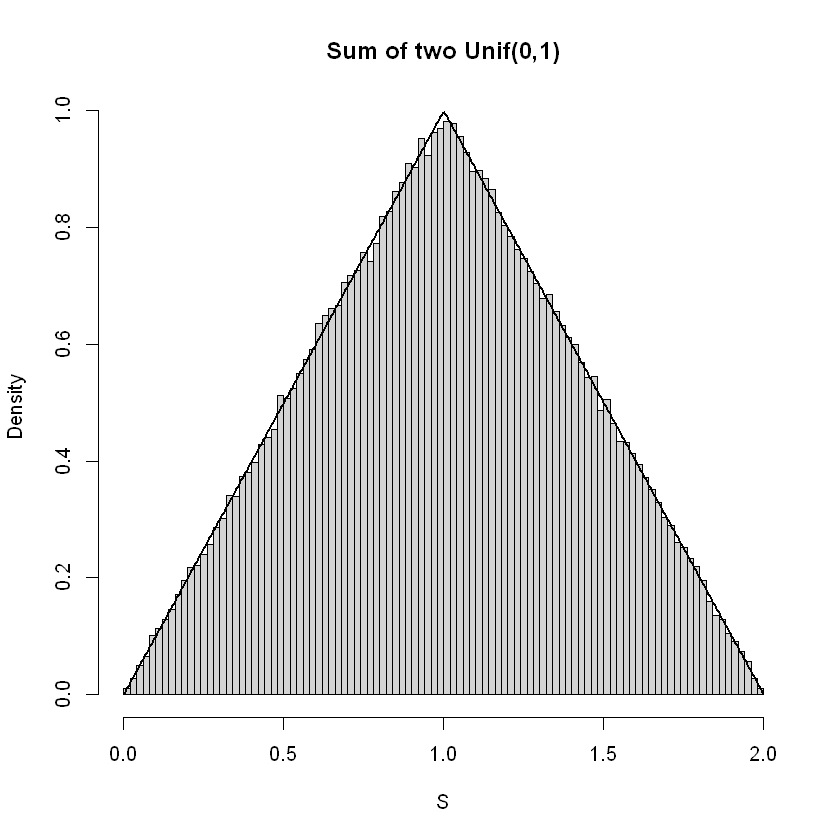

In [13]:
# === Plot scaffold ===
hist(S, breaks=100, probability=TRUE, main="Sum of two Unif(0,1)")
xs <- seq(0,2,length=500)
tri_pdf <- ifelse(xs<=1, xs, 2-xs)  # unnormalized; divide by 1? (density integrates to 1 as is on 0..2)
lines(xs, tri_pdf, lwd=2)

---
## Problem 4 — Conditional distributions (discrete & continuous) (12 pts)

(a) If $(X\sim\text{Pois}(\lambda_1)$, $Y\sim\text{Pois}(\lambda_2))$ indep., show $(X|X+Y=n\sim \text{Bin}(n, \lambda_1/(\lambda_1+\lambda_2)))$. Validate by simulation.  
(b) For $(f(x,y)=\frac{1}{y}e^{-x/y}e^{-y})$ on $(x>0,y>0)$: derive $(f_{X|Y}(x|y))$ and $(P\{X>1|Y=y\})$. Validate numerically.

**Your plan/derivation:** _(brief)_

By independence $P\{X+Y=n\}=\sum_{j=0}^{n}P\{X=j\}\,P\{Y=n-j\}=\sum_{j=0}^{n} e^{-\lambda_1}\frac{\lambda_1^{j}}{j!}\; e^{-\lambda_2}\frac{\lambda_2^{n-j}}{(n-j)!}$

$=e^{-(\lambda_1+\lambda_2)}\,\frac{1}{n!}\sum_{j=0}^{n}\frac{n!}{j!\,(n-j)!}\lambda_1^{j}\lambda_2^{n-j} =e^{-(\lambda_1+\lambda_2)}\,\frac{1}{n!}\sum_{j=0}^{n}\binom{n}{j}\lambda_1^{j}\lambda_2^{n-j}=e^{-(\lambda_1+\lambda_2)}\,\frac{(\lambda_1+\lambda_2)^n}{n!}$

so $X+Y\sim\text{Pois}(\lambda_1+\lambda_2)$

For $0\le k\le n$, $\{X=k\}\cap\{X+Y=n\}=\{X=k,\,Y=n-k\}$

$P\{X=k,\,X+Y=n\}=P\{X=k\}\,P\{Y=n-k\}=e^{-(\lambda_1+\lambda_2)}\frac{\lambda_1^{k}\lambda_2^{n-k}}{k!\,(n-k)!}$

$P\{X=k\mid X+Y=n\}=\frac{e^{-(\lambda_1+\lambda_2)}\dfrac{\lambda_1^{k}\lambda_2^{n-k}}{k!\,(n-k)!}}{e^{-(\lambda_1+\lambda_2)}\dfrac{(\lambda_1+\lambda_2)^n}{n!}}=\frac{n!}{k!\,(n-k)!}\cdot\frac{\lambda_1^{k}\lambda_2^{n-k}}{(\lambda_1+\lambda_2)^{k}(\lambda_1+\lambda_2)^{n-k}}=\binom{n}{k}\left(\frac{\lambda_1}{\lambda_1+\lambda_2}\right)^{k}\left(\frac{\lambda_2}{\lambda_1+\lambda_2}\right)^{n-k}$

which is the $\text{Bin}\left(n, \lambda_1/(\lambda_1+\lambda_2)\right)$ pmf

In [14]:
# === Part (a) ===
lam1 <- 2; lam2 <- 3; n <- 8  # example values; feel free to vary
# Compute theoretical binomial pmf; simulate many pairs and condition on X+Y==n.
p <- lam1 / (lam1 + lam2)
k <- 0:n
binom <- dbinom(k, n, p)
theoretical <- choose(n, k) * p^k * (1 - p)^(n - k)
max(abs(binom - theoretical))

N <- 1e6
X <- rpois(N, lam1)
Y <- rpois(N, lam2)
sel <- X[X + Y == n]
emp <- tabulate(sel + 1, nbins = n + 1) / length(sel)
round(rbind(k, binomial_approx = binom, empirical = emp), 4)

[1] 1.387779e-16

k,0.0000,1.0000,2.0000,3.0000,4.0000,5.0000,6.0000,7.0000,8e+00
binomial_approx,0.0168,0.0896,0.2090,0.2787,0.2322,0.1239,0.0413,0.0079,7e-04
empirical,0.0169,0.0909,0.2079,0.2790,0.2334,0.1226,0.0408,0.0076,7e-04


Let $u=x/y$, $dx=y\,du$, $f_Y(y)=\int_0^\infty f(x,y),dx =e^{-y}\int_0^\infty \frac{1}{y}e^{-x/y}\,dx =e^{-y}\int_0^\infty \frac{1}{y}e^{-u}\,y\,du =e^{-y}\int_0^\infty e^{-u}\,du =e^{-y}\big[-e^{-u}\big]_0^\infty=e^{-y}$

Since $f_Y(y)=e^{-y}>0$ for all $y>0$, $f_{X|Y}(x\mid y)=\frac{f(x,y)}{f_Y(y)}=\frac{\frac{1}{y}e^{-x/y}e^{-y}}{e^{-y}}=\frac{1}{y}e^{-x/y},\quad x>0$

$P\{X>1\mid Y=y\} =\int_1^\infty f_{X\mid Y}(x\mid y)\,dx =\int_1^\infty \frac{1}{y}e^{-x/y}\,dx =\Big[-e^{-x/y}\Big]_{x=1}^{x=\infty} =0-\big(-e^{-1/y}\big)=e^{-1/y}$

In [15]:
# === Part (b) ===
# Define joint f; derive conditional density; compute P(X>1|Y=y) function in R; compare to numerical integration.
f <- function(x, y) (1 / y) * exp(-x / y) * exp(-y)
fY <- function(y) integrate(function(x) f(x, y), 0, Inf)$value
f_cond <- function(x, y) f(x, y) / fY(y)
p_exact <- function(y) exp(-1 / y)

sapply(c(0.5, 1, 2), function(y) c(numeric = fY(y), exact = exp(-y)))
f_cond(c(0.3, 1, 2.5), 2)
dexp(c(0.3, 1, 2.5), rate = 1/2)

p_num <- function(y) integrate(function(x) f_cond(x, y), 1, Inf)$value
ygrid <- c(0.25, 0.5, 1, 2, 3, 5)
round(rbind(y = ygrid, numeric = sapply(ygrid, p_num), exact = p_exact(ygrid)), 5)

# === Plot scaffold ===
# For (a): barplot of theoretical vs empirical conditional pmf
# For (b): curve of P(X>1|Y=y) vs y with simulated estimates at a grid overlayed

numeric,0.6065307,0.3678794,0.1353353
exact,0.6065307,0.3678794,0.1353353


[1] 0.4303540 0.3032653 0.1432524

[1] 0.4303540 0.3032653 0.1432524

y,0.25000,0.50000,1.00000,2.00000,3.00000,5.00000
numeric,0.01832,0.13534,0.36788,0.60653,0.71653,0.81873
exact,0.01832,0.13534,0.36788,0.60653,0.71653,0.81873


---
## Problem 5 — Order statistics & the range (12 pts)

$(X_1,\dots,X_n\stackrel{iid}{\sim}U(0,1))$.  
1) Derive pdf/CDF of range $(R=X_{(n)}-X_{(1)})$.  
2) For $(n\in\{5,10,50\})$, simulate R (≥ \(10^5\) each) and compare ECDF to theory.  
3) For $(n=9)$, compute $(P\{1/4< X_{(5)} < 3/4\})$ analytically and via simulation.

**Your plan/derivation:** _(brief)_

Let $i=1$, $j=n$

$f_{X_{(1)},X_{(n)}}(x_1,x_n)=\frac{n!}{(n-2)!}\,[F(x_n)-F(x_1)]^{n-2}f(x_1)f(x_n)$

For $U(0,1)$, $F(x)=x$ and $f(x)=1$ on $(0,1)$, so $f_{X_{(1)},X_{(n)}}(x_1,x_n)=n(n-1)(x_n-x_1)^{n-2}, \text{ where } 0<x_1<x_n<1$

$P\{R\le a\}=\iint_{x_n-x_1\le a} f_{X_{(1)},X_{(n)}}(x_1,x_n)\,dx_1\,dx_n$ for $0<a<1$:

$P\{R\le a\}=\int_0^{1-a}\int_{x_1}^{x_1+a} n(n-1)(x_n-x_1)^{n-2}\,dx_n\,dx_1+\int_{1-a}^{1}\int_{x_1}^{1} n(n-1)(x_n-x_1)^{n-2}\,dx_n\,dx_1$

Since $x_n \leq 1$, the upper limit of $x_n$ is $\text{min}\left(x_1 +a,1\right)$, so we split at $x_1=1-a$

$\int_{x_1}^{x_1+a} n(n-1)(x_n-x_1)^{n-2}\,dx_n = n\,a^{n-1}$

$\int_{x_1}^{1} n(n-1)(x_n-x_1)^{n-2}\,dx_n = n(1-x_1)^{n-1}$

$P\{R\le a\}=\int_0^{1-a} n\,a^{n-1}\,dx_1+\int_{1-a}^{1} n(1-x_1)^{n-1}\,dx_1$

$\int_0^{1-a} n\,a^{n-1}\,dx_1 = n(1-a)a^{n-1}$

$\int_{1-a}^{1} n(1-x_1)^{n-1}\,dx_1 = a^n \text{ where } (u=1-x_1)$

$F_R(a)=n(1-a)a^{n-1}+a^n = n\,a^{n-1}-(n-1)\,a^n, \text{ where } 0<a<1$

$f_R(a)=\frac{d}{da}F_R(a)=n(n-1)a^{n-2}-n(n-1)a^{n-1}=n(n-1)a^{n-2}(1-a), \text{ where } 0<a<1$

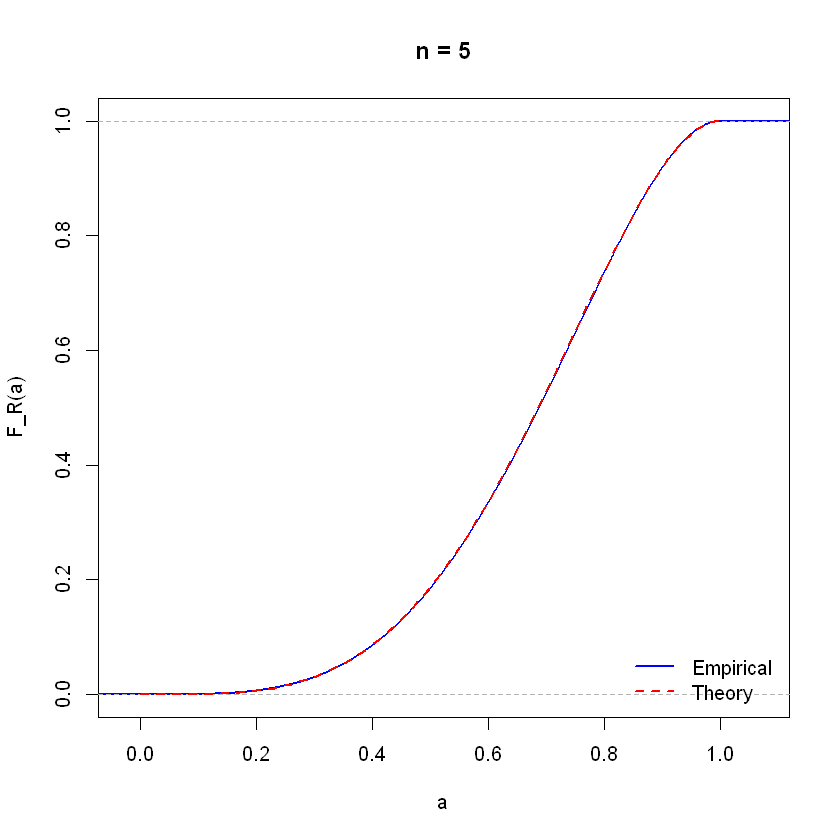

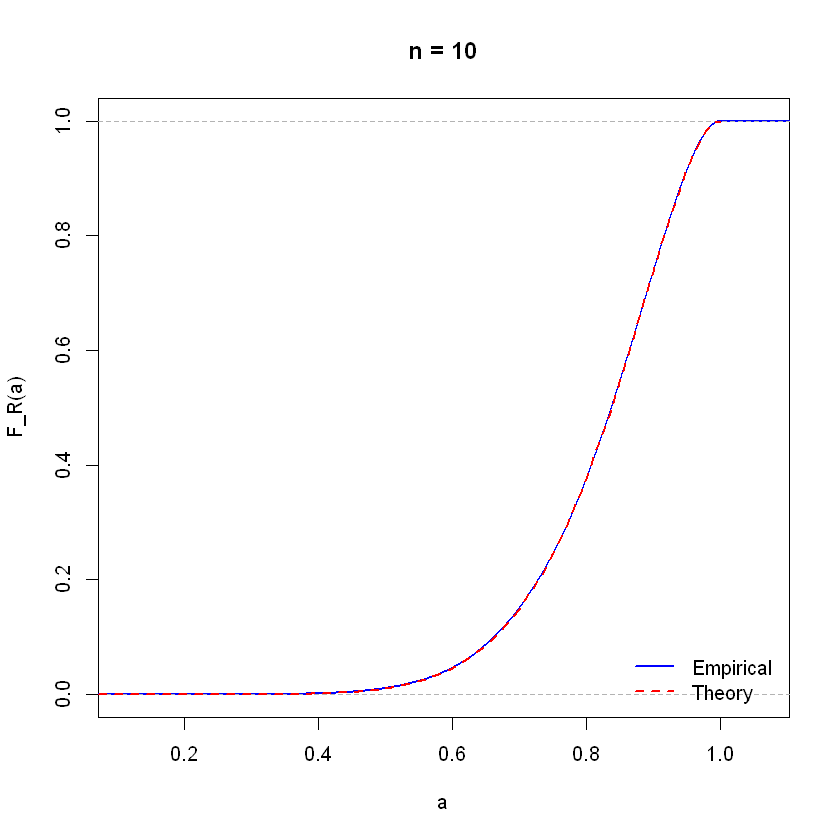

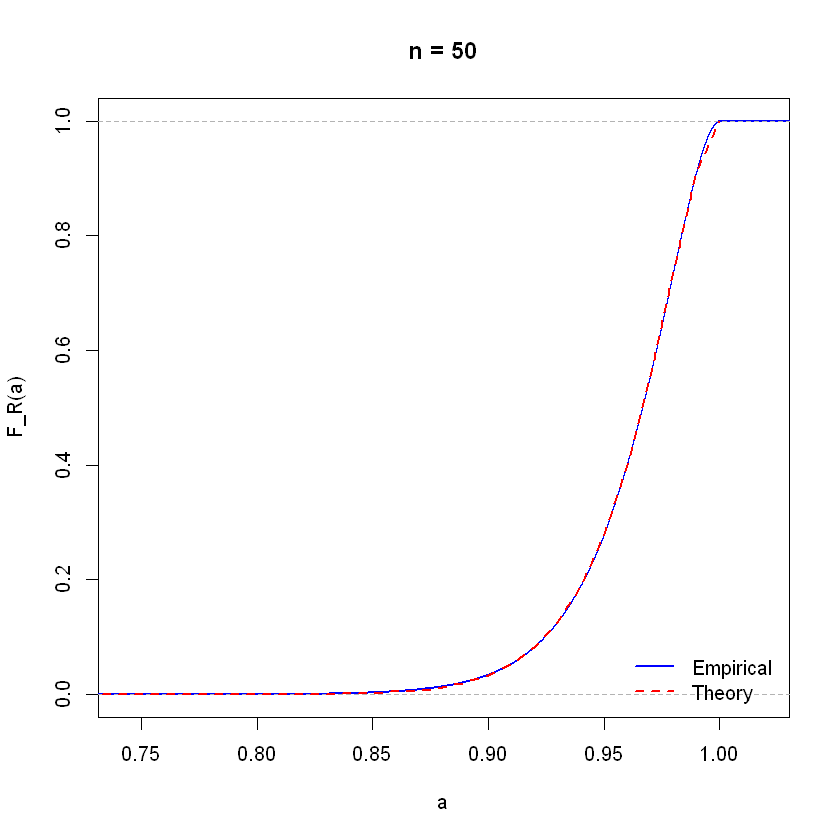

In [16]:
# === Analytic pieces ===
# Write functions for theoretical CDF/pdf of range for Unif(0,1)
pdf_R <- function(r, n) ifelse(r > 0 & r < 1, n*(n-1)*r^(n-2)*(1-r), 0)
cdf_R <- function(a, n) ifelse(a <= 0, 0, ifelse(a >= 1, 1, n*a^(n-1) - (n-1)*a^n))

# === Simulation ===
ns <- c(5,10,50)
# For each n, simulate many samples, compute range, compare ECDFs to theory
N  <- 1e5
sim_R <- list()
for (n in ns) {
  U <- matrix(runif(N * n), nrow = N, ncol = n)
  sim_R[[as.character(n)]] <- apply(U, 1, function(x) max(x) - min(x))
}

# === Plot scaffold ===
# Plot ECDFs and overlay theoretical CDF; second panel plot density histogram with theoretical pdf
for (n in ns) {
    R <- sim_R[[as.character(n)]]
    par(mfrow=c(1,1))
    plot(ecdf(R), main = paste("n =", n), xlab = "a", ylab = "F_R(a)", col = "blue", lwd = 2)
    curve(cdf_R(x, n), from = 0, to = 1, add = TRUE, col = "red", lwd = 2, lty = 2)
    legend("bottomright", legend = c("Empirical", "Theory"), col = c("blue", "red"), lty = c(1, 2), lwd = 2, bty = "n")
}
par(mfrow=c(1,1))

$f_{X_{(5)}}(x)=\frac{9!}{4!\,4!}\,x^4(1-x)^4=630\,x^4(1-x)^4, \text{ where } 0<x<1$

$P\left\{\tfrac14<X_{(5)}<\tfrac34\right\}=630\int_{1/4}^{3/4}x^4(1-x)^4\,dx=630\int_{1/4}^{3/4}\left(x^4-4x^5+6x^6-4x^7+x^8\right)dx=630\left[\frac{x^5}{5}-\frac{2x^6}{3}+\frac{6x^7}{7}-\frac{x^8}{2}+\frac{x^9}{9}\right]_{1/4}^{3/4}$

$=\Big[126x^5-420x^6+540x^7-315x^8+70x^9\Big]_{1/4}^{3/4}=\frac{249318}{4^9}-\frac{12826}{4^9}=\frac{236492}{262144}=\frac{59123}{65536}= 0.9021$

In [17]:
U9  <- matrix(runif(N * 9), nrow = N, ncol = 9)
X5  <- apply(U9, 1, function(x) sort(x)[5])
p_sim <- mean(X5 > 1/4 & X5 < 3/4)
p_sim

[1] 0.90278

---
## Problem 6 — Sums of independent gammas & chi-square (10 pts)

1) Prove closure: $(\Gamma(\alpha,\lambda)+\Gamma(\beta,\lambda)=\Gamma(\alpha+\beta,\lambda))$.  
2) Simulate with $((\alpha,\beta,\lambda)=(2.5,3.5,1.2))$; estimate mean/var of $(X+Y)$; overlay histogram with theoretical pdf.

**Your plan/derivation:** _(brief)_

The MGF of a gamma is $M_X(t)=E[e^{tX}]$

For $t<\lambda$, $M_X(t)=\int_0^\infty e^{tx}\,\frac{\lambda^\alpha}{\Gamma(\alpha)}x^{\alpha-1}e^{-\lambda x}\,dx=\frac{\lambda^\alpha}{\Gamma(\alpha)}\int_0^\infty x^{\alpha-1}e^{-(\lambda-t)x}\,dx.$

This is a gamma density with rate $\lambda-t$, without a constant. 

Since gamma density with rate $\lambda-t$ integrates to 1,

$=\int_0^\infty x^{\alpha-1}e^{-(\lambda-t)x}\,dx=\frac{\Gamma(\alpha)}{(\lambda-t)^\alpha}=\frac{\lambda^\alpha}{(\lambda-t)^\alpha}=\left(\frac{\lambda}{\lambda-t}\right)^{\alpha}$

and $M_Y(t)=\left(\frac{\lambda}{\lambda-t}\right)^{\beta}$.

$e^{t(X+Y)}=e^{tX}e^{tY}$ and $X,Y$ are independent, so

$M_{X+Y}(t)=E\left[e^{tX}e^{tY}\right]=E\left[e^{tX}\right]E\left[e^{tY}\right]=M_X(t)\,M_Y(t)$

Both MGFs have the same base so the exponents add

$M_{X+Y}(t)=\left(\frac{\lambda}{\lambda-t}\right)^{\alpha}\left(\frac{\lambda}{\lambda-t}\right)^{\beta}=\left(\frac{\lambda}{\lambda-t}\right)^{\alpha+\beta}$

which is the MGF of the gamma $\Gamma(\alpha+\beta,\lambda)$ with shape $\alpha+\beta$

In [18]:
# === Theory check helpers ===
# dgam_shape_rate <- function(x, shape, rate) dgamma(x, shape=shape, rate=rate)

# === Simulation ===
# set.seed(631)
N <- 2e5
alpha <- 2.5; beta <- 3.5; lambda <- 1.2
X <- rgamma(N, shape=alpha, rate=lambda)
Y <- rgamma(N, shape=beta, rate=lambda)
S <- X + Y
mean_hat <- mean(S); var_hat <- var(S)

mean_hat
(alpha + beta) / lambda
var_hat
(alpha + beta) / lambda^2

[1] 5.007646

[1] 5

[1] 4.172538

[1] 4.166667

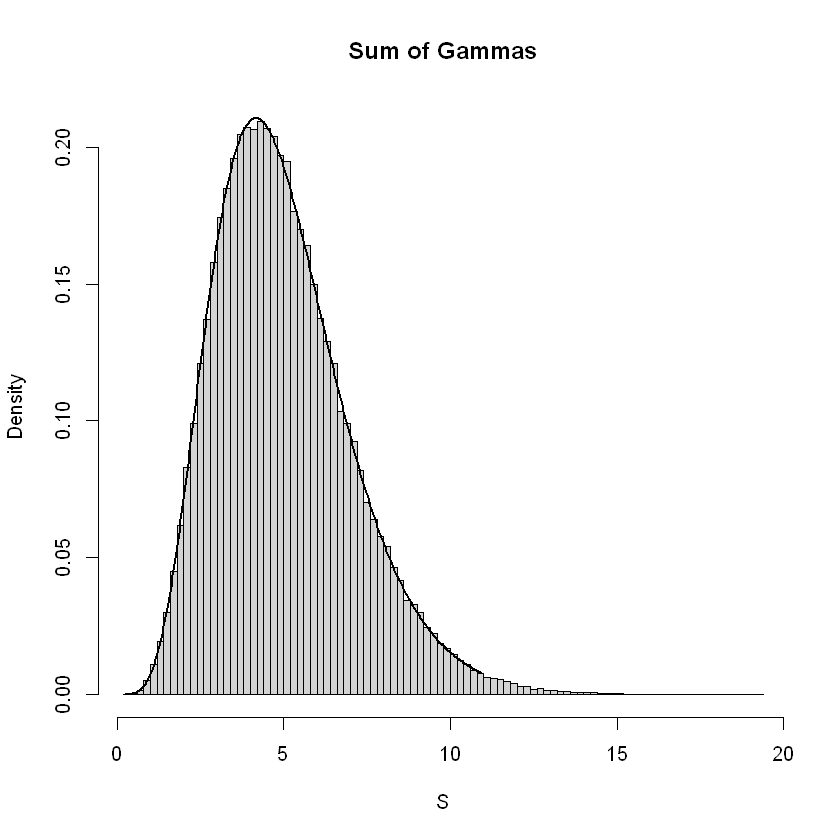

In [19]:
# === Plot scaffold ===
hist(S, breaks=120, probability=TRUE, main="Sum of Gammas")
xs <- seq(min(S), quantile(S,0.99), length=400)
lines(xs, dgamma(xs, shape=alpha+beta, rate=lambda), lwd=2)

---
## Problem 7 — Transformations & Jacobians (bivariate) (16 pts)

(a) Polar transform for $(X,Y\sim iid\ N(0,1))$: show $(R\perp\!\!\perp\Theta)$ with $(f_{R,\Theta}(r,\theta)=\frac{1}{2\pi}re^{-r^2/2})$. Validate by simulation.  
(b) $(U=X+Y, V=X/(X+Y))$ with $(X\sim\Gamma(\alpha,\lambda)$, $Y\sim\Gamma(\beta,\lambda))$ indep. Show $(U\sim\Gamma(\alpha+\beta,\lambda)$, $V\sim\mathrm{Beta}(\alpha,\beta))$, independence. Validate.

**Your plan/derivation:** _(brief)_

Let $x=r\cos\theta$, $y=r\sin\theta$

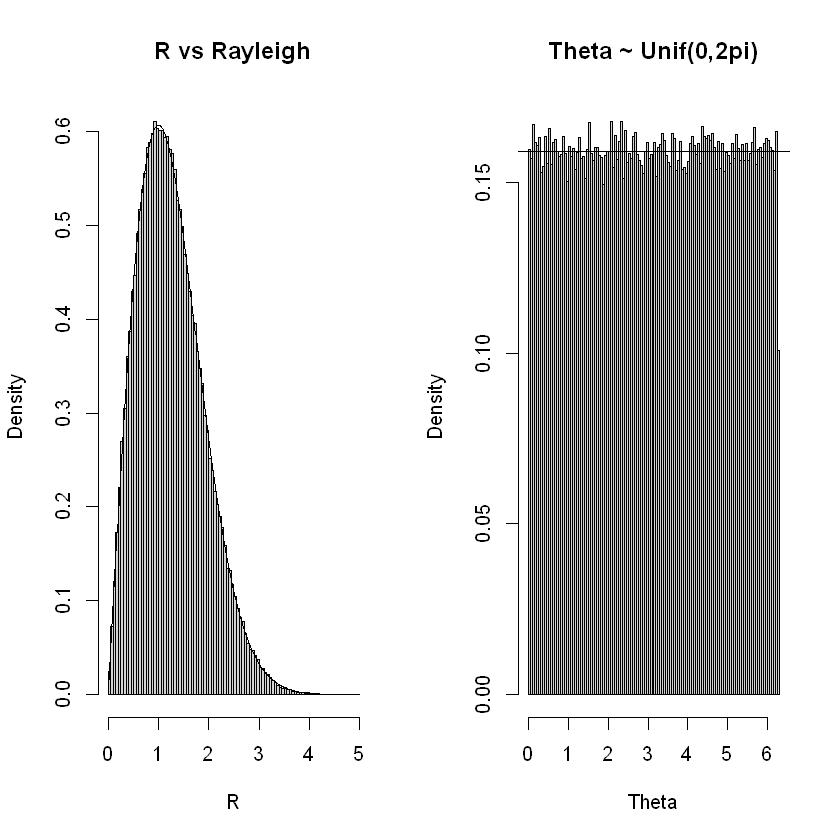

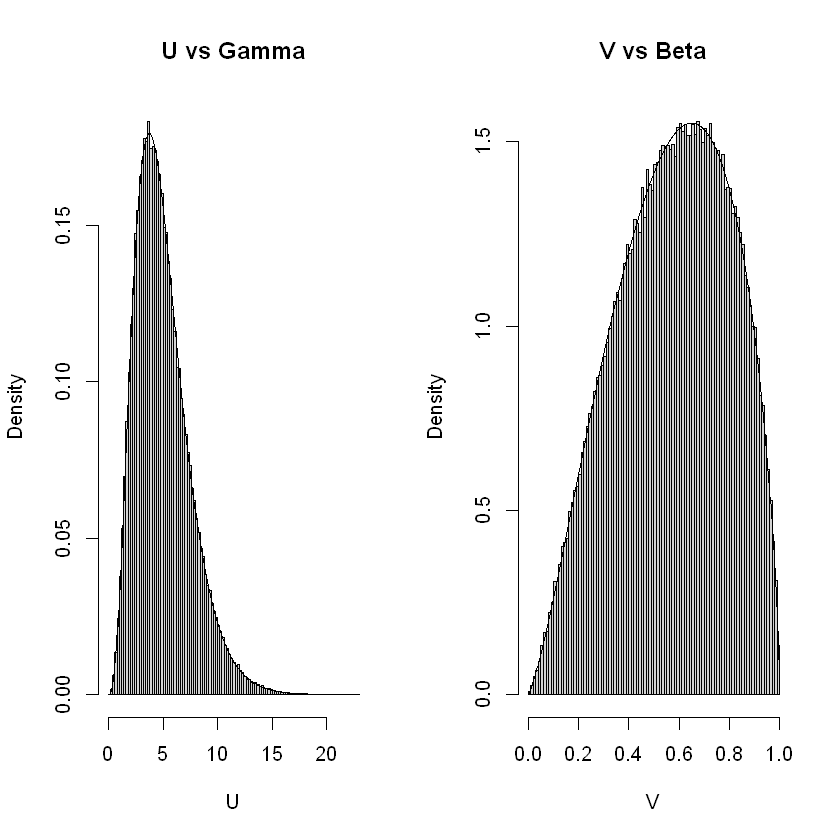

In [20]:
# === Part (a) simulation ===
N <- 2e5
X <- rnorm(N); Y <- rnorm(N)
R <- sqrt(X^2 + Y^2); Theta <- atan2(Y, X) %% (2*pi)
# Check empirical independence via cor(R,Theta) ~ 0 (note circular caveats); compare marginals to theory.

# === Plot scaffold ===
par(mfrow=c(1,2))
hist(R, breaks=120, probability=TRUE, main="R vs Rayleigh")
curve(x*exp(-x^2/2), add=TRUE, n=500)
hist(Theta, breaks=100, probability=TRUE, main="Theta ~ Unif(0,2pi)")
abline(h=1/(2*pi))

# === Part (b) simulation ===
alpha <- 2.3; beta <- 1.7; lambda <- 0.8
Xg <- rgamma(N, shape=alpha, rate=lambda)
Yg <- rgamma(N, shape=beta,  rate=lambda)
U <- Xg + Yg
V <- Xg / (Xg + Yg)
# Compare to dgamma/dbeta; check cor(U,V) ~ 0

# === Plot scaffold ===
par(mfrow=c(1,2))
hist(U, breaks=120, probability=TRUE, main="U vs Gamma")
curve(dgamma(x, shape=alpha+beta, rate=lambda), add=TRUE, n=500)
hist(V, breaks=120, probability=TRUE, main="V vs Beta")
curve(dbeta(x, shape1=alpha, shape2=beta), add=TRUE, n=500)

---
## Problem 8 — Sums & mixtures in practice (Poisson splitting / multinomial) (16 pts)

1) **Poisson splitting:** show $(N_A\sim\text{Pois}(\lambda p))$, $(N_B\sim\text{Pois}(\lambda(1-p)))$, independence. Validate simulation for several $((\lambda,p))$.  
2) **Multinomial counts:** for $(\mathbf p=(0.1,0.2,0.3,0.4), n=200)$: compute theory for means/vars/covariances; simulate $10^5$ replicates; compare; heatmap of $(X_1,X_2)$.

**Your plan/derivation:** _(brief)_

$N_A \mid N=m \sim \mathrm{Bin}(m,p)$ and $N_B = m - N_A$.

For $a,b \ge 0$, let $m=a+b$.

$P(N_A=a, N_B=b) = P(N=a+b)\, P(N_A=a \mid N=a+b)=\frac{e^{-\lambda}\lambda^{a+b}}{(a+b)!} \cdot \frac{(a+b)!}{a!\,b!}\, p^a (1-p)^b= \frac{e^{-\lambda}\lambda^a \lambda^b p^a (1-p)^b}{a!\,b!}$

Since $e^{-\lambda} = e^{-\lambda p}\, e^{-\lambda(1-p)}$

$=\frac{e^{-\lambda p}(\lambda p)^a}{a!} \cdot \frac{e^{-\lambda(1-p)}(\lambda(1-p))^b}{b!}$

This is a function of $a$ times a function of $b$, so $N_A$ and $N_B$ are independent

$\sum_{b=0}^{\infty} \frac{e^{-\lambda(1-p)}(\lambda(1-p))^b}{b!} = e^{-\lambda(1-p)} \sum_{b=0}^{\infty} \frac{(\lambda(1-p))^b}{b!}= e^{-\lambda(1-p)} \, e^{\lambda(1-p)} = 1$

This is the Taylor series of $e^x$ 

So summing over $b$ gives $P(N_A=a) = \frac{e^{-\lambda p}(\lambda p)^a}{a!}$

$N_A \sim \mathrm{Pois}(\lambda p)$

$N_B \sim \mathrm{Pois}(\lambda(1-p))$

In [21]:
# === Part 1: Poisson splitting ===
reps <- 1e5
lam <- 7; p <- 0.3
N  <- rpois(reps, lam)
N_A <- rbinom(reps, N, p)
NB <- N - N_A
# Check means/vars vs lam*p and lam*(1-p); cor(NA, NB) should be ~0
mean(N_A)
var(N_A)
lam * p
mean(NB)
var(NB)
lam * (1 - p)
cor(N_A, NB)

[1] 2.09768

[1] 2.09894

[1] 2.1

[1] 4.90885

[1] 4.956831

[1] 4.9

[1] 0.006775228

In [25]:
sim <- function(lam, p, reps = 1e5) {
    N <- rpois(reps, lam)
    N_A <- rbinom(reps, N, p)
    NB <- N - N_A
    ct <- cor.test(N_A, NB)
    data.frame(lam = lam, p = p, mean_A = mean(N_A), ex_A = lam*p, mean_B = mean(NB), ex_B = lam*(1-p), cor = unname(ct$estimate), cor_p = ct$p.value)
}

grid <- expand.grid(lam = c(2, 7, 20), p = c(0.1, 0.5, 0.8))
res <- do.call(rbind, lapply(seq_len(nrow(grid)), function(i) sim(grid$lam[i], grid$p[i])))
round(res, 2)

lam,p,mean_A,ex_A,mean_B,ex_B,cor,cor_p
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2,0.1,0.20,0.2,1.80,1.8,0,0.74
7,0.1,0.70,0.7,6.33,6.3,0,0.29
20,0.1,2.00,2.0,18.01,18.0,0,0.56
2,0.5,1.00,1.0,1.00,1.0,0,0.83
7,0.5,3.49,3.5,3.50,3.5,0,0.84
20,0.5,10.00,10.0,10.01,10.0,0,0.35
2,0.8,1.60,1.6,0.40,0.4,0,0.20
7,0.8,5.61,5.6,1.40,1.4,0,0.16
20,0.8,15.98,16.0,3.99,4.0,0,0.22


$X_i \sim \mathrm{Bin}(n,p_i)$

$E[X_i] = np_i$

$\mathrm{Var}(X_i) = np_i(1-p_i)$

For $i \neq j$, $X_i + X_j \sim \mathrm{Bin}(n, p_i+p_j)$

$\mathrm{Cov}(X_i,X_j) = \frac{1}{2}\Big[\mathrm{Var}(X_i+X_j) - \mathrm{Var}(X_i) - \mathrm{Var}(X_j)\Big] = \frac{n}{2}\Big[(p_i+p_j)(1-p_i-p_j) - p_i(1-p_i) - p_j(1-p_j)\Big] = -np_ip_j$

For $n=200$ and $p=(0.1,0.2,0.3,0.4)$:

$E[X_1] = 200(0.1) = 20$

$E[X_2] = 200(0.2) = 40$

$E[X_3] = 200(0.3) = 60$

$E[X_4] = 200(0.4) = 80$

$\mathrm{Var}(X_1) = 200(0.1)(0.9) = 18$

$\mathrm{Var}(X_2) = 200(0.2)(0.8) = 32$

$\mathrm{Var}(X_3) = 200(0.3)(0.7) = 42$

$\mathrm{Var}(X_4) = 200(0.4)(0.6) = 48$]

$\mathrm{Cov}(X_1,X_2) = -200(0.1)(0.2) = -4$

$\mathrm{Cov}(X_1,X_3) = -200(0.1)(0.3) = -6$

$\mathrm{Cov}(X_1,X_4) = -200(0.1)(0.4) = -8$

$\mathrm{Cov}(X_2,X_3) = -200(0.2)(0.3) = -12$

$\mathrm{Cov}(X_2,X_4) = -200(0.2)(0.4) = -16$

$\mathrm{Cov}(X_3,X_4) = -200(0.3)(0.4) = -24$

In [23]:
# === Part 2: Multinomial ===
n <- 200; pvec <- c(0.1,0.2,0.3,0.4)
reps <- 1e5
X <- t(rmultinom(reps, size=n, prob=pvec))
# Compute sample means/vars/covs and compare to theory
sample_mean <- colMeans(X)
sample_cov <- cov(X)
sample_var <- diag(sample_cov)
round(sample_mean, 1)
round(sample_var, 1)
round(sample_cov, 1)

[1] 20 40 60 80

[1] 18.0 32.0 42.2 48.0

18.0,-3.9,-6.2,-8.0
-3.9,32.0,-12.0,-16.1
-6.2,-12.0,42.2,-24.0
-8.0,-16.1,-24.0,48.0


[1] -0.1604841

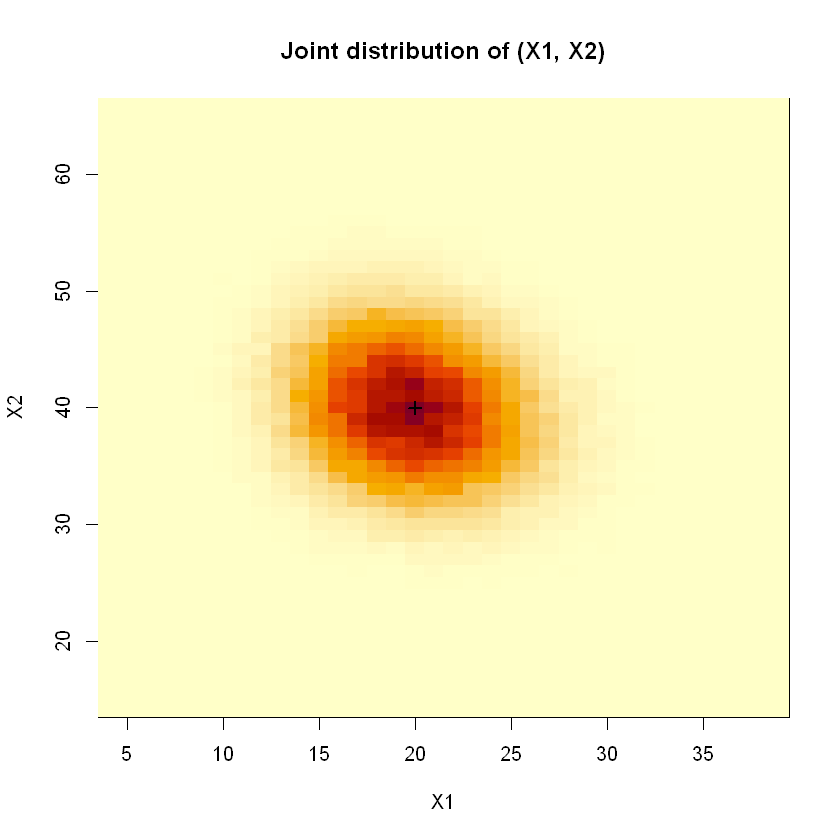

In [24]:
# === Plot scaffold ===
# Heatmap for joint (X1,X2): build a 2D table (maybe coarse binning) and image()
r1 <- min(X[,1]):max(X[,1])
r2 <- min(X[,2]):max(X[,2])
tab <- table(factor(X[,1], levels = r1), factor(X[,2], levels = r2))
M <- unclass(tab) / reps
image(r1, r2, M, col = hcl.colors(50, "YlOrRd", rev = TRUE), xlab = "X1", ylab = "X2", main = "Joint distribution of (X1, X2)")
points(sample_mean[1], sample_mean[2], pch = 3, lwd = 2)
cor(X[,1], X[,2])

---
## Implementation & Style Checklist
- Fixed seed; restart & run all is clean.
- Provide short interpretation after each result.
- Include 95% CIs where appropriate.